In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (8807, 12)


In [16]:
# Column names
print("Columns:")
print(df.columns.tolist())

Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [15]:
# Data types and non-null counts
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [14]:
# Missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [13]:
# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [12]:
# Statistical summary
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN



# Netflix Movies and TV Shows — Exploratory Data Analysis

## Objectives
1. How many Movies and TV Shows are present in the dataset?
2. Which years have the highest number of Netflix releases?
3. Which countries contribute the most titles?
4. Which genres are most common?
5. How many missing values and duplicate records exist?
6. Is there a relationship between a title's release year and its content type?

## Hypotheses
- H1: Movies are more numerous than TV Shows.
- H2: The number of titles released per year has changed over time.
- H3: The distribution of release years differs between Movies and TV Shows.


In [17]:
# Q1-Number of Movies and TV Shows
print("Content Type Counts:")
print(df["type"].value_counts())

Content Type Counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [18]:
#Q2-Percentage of each content type
print("\nContent Type Percentages:")
print((df["type"].value_counts(normalize=True) * 100).round(2))


Content Type Percentages:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


In [19]:
#Q3-Release year range
print("\nEarliest release year:", df["release_year"].min())
print("Latest release year:", df["release_year"].max())


Earliest release year: 1925
Latest release year: 2021


In [20]:
#Q4- Most common ratings
print("\nTop 10 Ratings:")
print(df["rating"].value_counts().head(10))


Top 10 Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


In [21]:
#Q5- Most common countries
print("\nTop 10 Countries:")
print(df["country"].dropna().str.split(", ").explode().value_counts().head(10))


Top 10 Countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


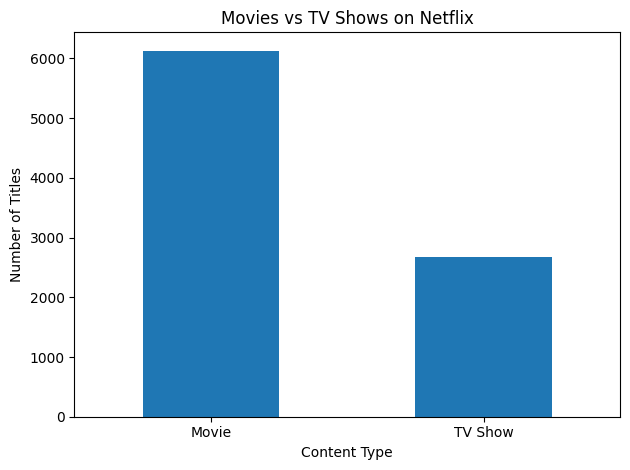

In [22]:
content_counts = df["type"].value_counts()

content_counts.plot(kind="bar")
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
# Check missing values in each column
# df.isnull() identifies missing values (True/False)
# .sum() counts missing values column-wise
missing_values = df.isnull().sum()

# Display the missing values count for each column
print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [24]:
# Check duplicate records in the Netflix dataset
# duplicated() identifies rows that are repeated
# sum() counts the total number of duplicate rows

duplicate_count = df.duplicated().sum()

# Display the total number of duplicate records
print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [25]:
# Check the data type of each column
# dtypes tells us whether a column contains integers,
# text, floating-point numbers, or other data types

data_types = df.dtypes

# Display the data type of every column
print("Data Types of Each Column:")
print(data_types)

Data Types of Each Column:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


In [27]:
# Display basic information about the Netflix dataset
# info() shows column names, non-null values, and data types

print("Netflix Dataset Information:")

# Display dataset structure and memory information
df.info()

Netflix Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [28]:
# Generate a statistical summary of numerical columns
# describe() calculates count, mean, standard deviation,
# minimum, maximum, and quartiles

print("Statistical Summary of Netflix Dataset:")

# Display the summary statistics
print(df.describe())

Statistical Summary of Netflix Dataset:
       release_year
count   8807.000000
mean    2014.180198
std        8.819312
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000


In [29]:
# Check the number of unique values in each column
# nunique() counts distinct values and excludes missing values by default

print("Unique Values in Each Column:")

# Display the unique value count for every column
print(df.nunique())

Unique Values in Each Column:
show_id         8807
type               2
title           8807
director        4528
cast            7692
country          748
date_added      1767
release_year      74
rating            17
duration         220
listed_in        514
description     8775
dtype: int64


In [30]:
# Count the number of Movies and TV Shows
# value_counts() counts how many times each content type appears

content_counts = df["type"].value_counts()

# Display the count of each content type
print("Netflix Content Type Distribution:")
print(content_counts)

Netflix Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [31]:
# Calculate the percentage of each content type
# normalize=True converts counts into proportions
# Multiplying by 100 converts proportions into percentages

content_percentage = df["type"].value_counts(
    normalize=True
) * 100

# Round percentages to 2 decimal places
content_percentage = content_percentage.round(2)

# Display the percentage distribution
print("Netflix Content Type Percentage:")
print(content_percentage)

Netflix Content Type Percentage:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


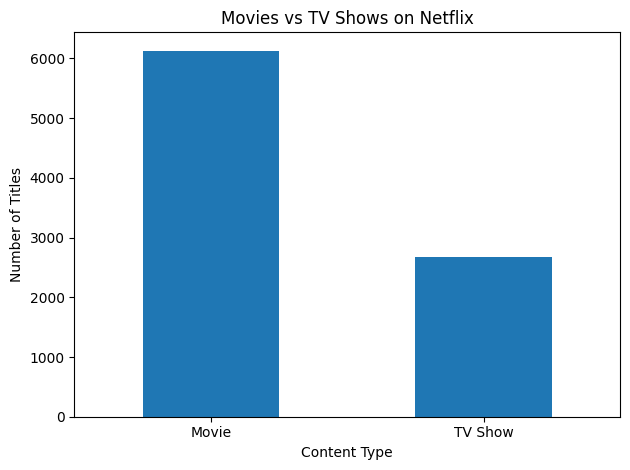

In [32]:
# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Count the number of Movies and TV Shows
content_counts = df["type"].value_counts()

# Create a bar chart
content_counts.plot(kind="bar")

# Add chart title and axis labels
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

# Keep category labels horizontal
plt.xticks(rotation=0)

# Adjust layout to prevent overlapping labels
plt.tight_layout()

# Display the chart
plt.show()

In [33]:
# Count the number of titles released in each year
# value_counts() counts titles for each release year
# sort_index() arranges the years in ascending order

year_counts = df["release_year"].value_counts().sort_index()

# Display the release year counts
print("Titles by Release Year:")
print(year_counts)

Titles by Release Year:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


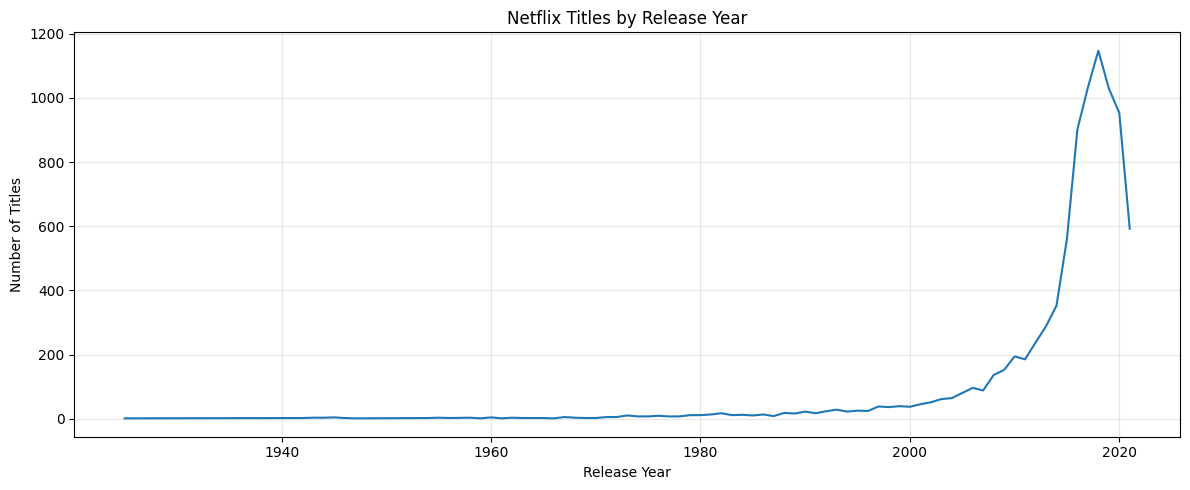

In [34]:
# Count titles released in each year
year_counts = df["release_year"].value_counts().sort_index()

# Create a figure with a suitable size
plt.figure(figsize=(12, 5))

# Plot the yearly title counts as a line chart
plt.plot(year_counts.index, year_counts.values)

# Add chart title and axis labels
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

# Add grid lines to make the chart easier to read
plt.grid(True, alpha=0.3)

# Adjust spacing around the chart
plt.tight_layout()

# Display the chart
plt.show()

In [35]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing values percentage for each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine counts and percentages into a DataFrame
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

# Display only columns that contain missing values
print("Missing Values Analysis:")
print(missing_summary[missing_summary["Missing Count"] > 0])

Missing Values Analysis:
            Missing Count  Missing Percentage
director             2634               29.91
cast                  825                9.37
country               831                9.44
date_added             10                0.11
rating                  4                0.05
duration                3                0.03


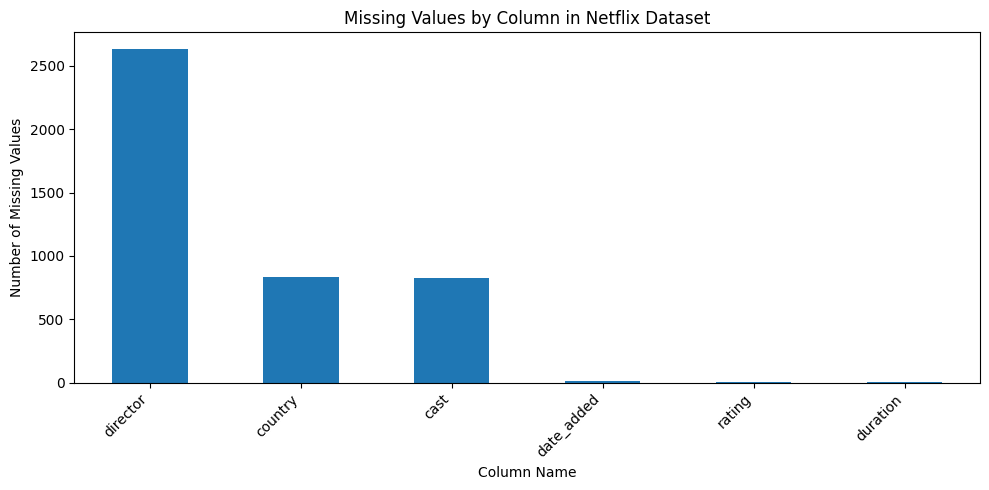

In [36]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Keep only columns that have missing values
missing_count = missing_count[missing_count > 0]

# Create a bar chart of missing values
plt.figure(figsize=(10, 5))
missing_count.sort_values(ascending=False).plot(kind="bar")

# Add chart title and axis labels
plt.title("Missing Values by Column in Netflix Dataset")
plt.xlabel("Column Name")
plt.ylabel("Number of Missing Values")

# Rotate labels for better readability
plt.xticks(rotation=45, ha="right")

# Adjust chart spacing
plt.tight_layout()

# Display the chart
plt.show()

In [37]:
# Select the country column and remove missing values
country_data = df["country"].dropna()

# Split entries containing multiple countries
# explode() creates a separate row for each country
country_counts = (
    country_data.str.split(", ")
    .explode()
    .value_counts()
)

# Select the top 10 countries by title count
top_10_countries = country_counts.head(10)

# Display the results
print("Top 10 Countries by Netflix Titles:")
print(top_10_countries)

Top 10 Countries by Netflix Titles:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


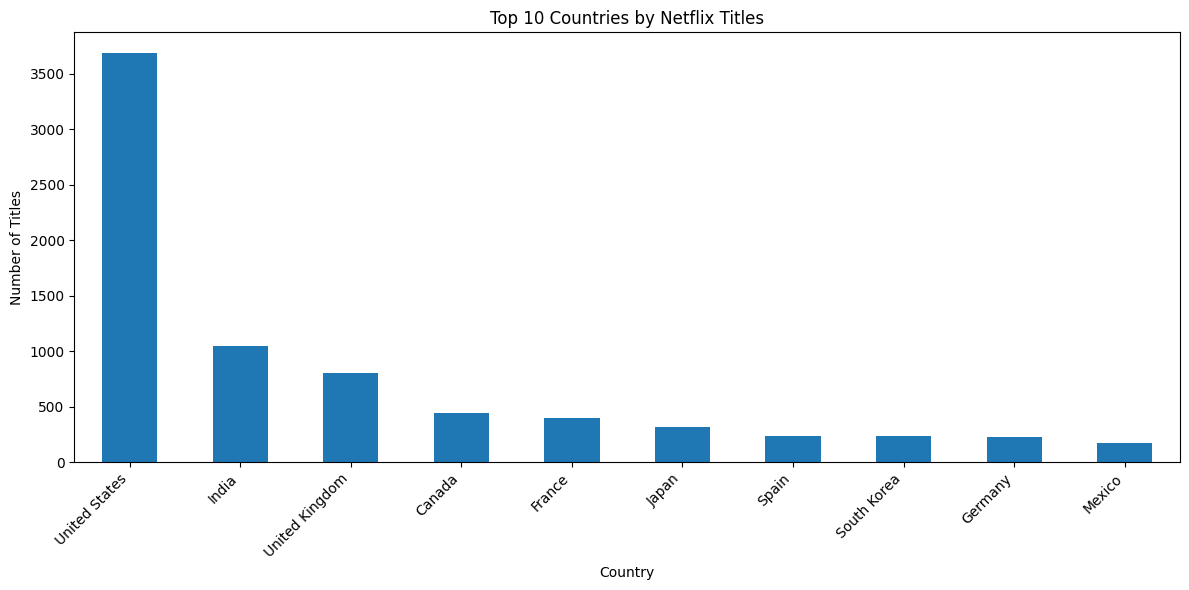

In [38]:
# Select the country column and remove missing values
country_data = df["country"].dropna()

# Split multiple countries listed in a single cell
# explode() places each country in a separate row
country_counts = (
    country_data.str.split(", ")
    .explode()
    .value_counts()
)

# Select the top 10 countries
top_10_countries = country_counts.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))
top_10_countries.plot(kind="bar")

# Add chart title and axis labels
plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")

# Rotate country names for readability
plt.xticks(rotation=45, ha="right")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [39]:
# Select the listed genres and remove missing values
genre_data = df["listed_in"].dropna()

# Split multiple genres listed in a single cell
# explode() places each genre into a separate row
genre_counts = (
    genre_data.str.split(", ")
    .explode()
    .value_counts()
)

# Select the top 10 most common genres
top_10_genres = genre_counts.head(10)

# Display the results
print("Top 10 Most Common Netflix Genres:")
print(top_10_genres)

Top 10 Most Common Netflix Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


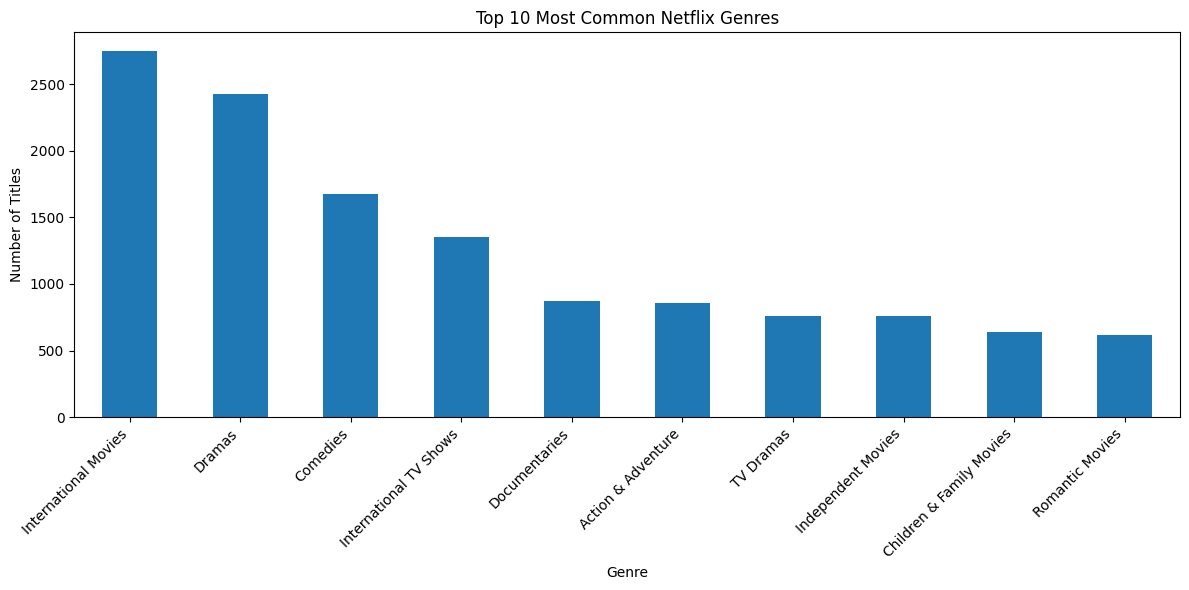

In [40]:
# Select the genre column and remove missing values
genre_data = df["listed_in"].dropna()

# Split multiple genres listed in one cell
# explode() puts each genre into a separate row
genre_counts = (
    genre_data.str.split(", ")
    .explode()
    .value_counts()
)

# Select the 10 most common genres
top_10_genres = genre_counts.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))
top_10_genres.plot(kind="bar")

# Add chart title and axis labels
plt.title("Top 10 Most Common Netflix Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")

# Rotate labels so they are easier to read
plt.xticks(rotation=45, ha="right")

# Adjust the chart layout
plt.tight_layout()

# Display the chart
plt.show()

In [41]:
# Display the duration column for Movies and TV Shows
# duration contains movie runtime or number of seasons

print("Duration Examples:")

# Show the first 10 titles with their content type and duration
print(df[["title", "type", "duration"]].head(10))

Duration Examples:
                              title     type   duration
0              Dick Johnson Is Dead    Movie     90 min
1                     Blood & Water  TV Show  2 Seasons
2                         Ganglands  TV Show   1 Season
3             Jailbirds New Orleans  TV Show   1 Season
4                      Kota Factory  TV Show  2 Seasons
5                     Midnight Mass  TV Show   1 Season
6  My Little Pony: A New Generation    Movie     91 min
7                           Sankofa    Movie    125 min
8     The Great British Baking Show  TV Show  9 Seasons
9                      The Starling    Movie    104 min


In [42]:
# Select only Movies from the Netflix dataset
movies_df = df[df["type"] == "Movie"].copy()

# Extract the numeric part from duration values such as "90 min"
# Non-numeric or missing values will become NaN
movies_df["duration_minutes"] = pd.to_numeric(
    movies_df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Display the first 10 Movies with their original and numeric duration
print("Movie Duration in Minutes:")
print(movies_df[["title", "duration", "duration_minutes"]].head(10))

Movie Duration in Minutes:
                                                title duration  \
0                                Dick Johnson Is Dead   90 min   
6                    My Little Pony: A New Generation   91 min   
7                                             Sankofa  125 min   
9                                        The Starling  104 min   
12                                       Je Suis Karl  127 min   
13                   Confessions of an Invisible Girl   91 min   
16  Europe's Most Dangerous Man: Otto Skorzeny in ...   67 min   
18                                          Intrusion   94 min   
22                                    Avvai Shanmughi  161 min   
23       Go! Go! Cory Carson: Chrissy Takes the Wheel   61 min   

    duration_minutes  
0               90.0  
6               91.0  
7              125.0  
9              104.0  
12             127.0  
13              91.0  
16              67.0  
18              94.0  
22             161.0  
23              

In [43]:
# Calculate the average and median movie duration
# dropna() excludes movies with missing duration values

valid_durations = movies_df["duration_minutes"].dropna()

# Calculate average duration in minutes
average_duration = valid_durations.mean()

# Calculate median duration in minutes
median_duration = valid_durations.median()

# Display the results
print("Average Movie Duration:", round(average_duration, 2), "minutes")
print("Median Movie Duration:", median_duration, "minutes")

Average Movie Duration: 99.58 minutes
Median Movie Duration: 98.0 minutes


In [44]:
# Check for missing movie durations
missing_duration = movies_df["duration_minutes"].isnull().sum()

# Count movies with zero or negative duration
invalid_duration = (
    movies_df["duration_minutes"] <= 0
).sum()

# Calculate the first and third quartiles
q1 = movies_df["duration_minutes"].quantile(0.25)
q3 = movies_df["duration_minutes"].quantile(0.75)

# Calculate the interquartile range (IQR)
iqr = q3 - q1

# Define lower and upper limits for potential outliers
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Count potential outliers
outliers = (
    (movies_df["duration_minutes"] < lower_limit) |
    (movies_df["duration_minutes"] > upper_limit)
).sum()

# Display the results
print("Missing Durations:", missing_duration)
print("Zero or Negative Durations:", invalid_duration)
print("Potential Duration Outliers:", outliers)
print("Lower Outlier Limit:", lower_limit)
print("Upper Outlier Limit:", upper_limit)

Missing Durations: 3
Zero or Negative Durations: 0
Potential Duration Outliers: 450
Lower Outlier Limit: 46.5
Upper Outlier Limit: 154.5


In [46]:
# Import the binomial test from SciPy
from scipy.stats import binomtest

# Count Movies and TV Shows
content_counts = df["type"].value_counts()

movies_count = int(content_counts.get("Movie", 0))
tv_shows_count = int(content_counts.get("TV Show", 0))

# Calculate the total number of titles
total_titles = movies_count + tv_shows_count

# Display the observed counts
print("Movies:", movies_count)
print("TV Shows:", tv_shows_count)

# Test whether Movies make up more than half of the titles
# Null hypothesis: the Movie proportion is 50%
# Alternative hypothesis: the Movie proportion is greater than 50%
result = binomtest(
    movies_count,
    n=total_titles,
    p=0.5,
    alternative="greater"
)

# Display the p-value
print("P-value:", result.pvalue)

# Interpret the result using a 5% significance level
if result.pvalue < 0.05:
    print("Reject the null hypothesis.")
    print("Movies account for significantly more than half of the titles.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient statistical evidence that Movies exceed half of the titles.")

Movies: 6131
TV Shows: 2676
P-value: 6.860469409908226e-305
Reject the null hypothesis.
Movies account for significantly more than half of the titles.


In [47]:
# Calculate total titles in the Netflix dataset
total_titles = len(df)

# Count Movies and TV Shows
content_counts = df["type"].value_counts()

# Find the most common content type
most_common_type = content_counts.idxmax()

# Calculate the average movie duration
# Use the numeric duration column created earlier
average_movie_duration = movies_df["duration_minutes"].mean()

# Find the most common release year
most_common_release_year = df["release_year"].mode().iloc[0]

# Find the most common genre
# Split multiple genres and count each genre separately
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

most_common_genre = genre_counts.idxmax()

# Display the final findings
print("===== NETFLIX EDA FINAL SUMMARY =====")
print("Total Titles:", total_titles)
print("\nContent Type Counts:")
print(content_counts)
print("\nMost Common Content Type:", most_common_type)
print("Most Common Release Year:", most_common_release_year)
print("Most Common Genre:", most_common_genre)
print(
    "Average Movie Duration:",
    round(average_movie_duration, 2),
    "minutes"
)

===== NETFLIX EDA FINAL SUMMARY =====
Total Titles: 8807

Content Type Counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Most Common Content Type: Movie
Most Common Release Year: 2018
Most Common Genre: International Movies
Average Movie Duration: 99.58 minutes



## Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on the Netflix Movies and TV Shows dataset using Python.

The analysis included:
- Exploring the dataset structure and data types.
- Identifying missing values and duplicate records.
- Analyzing Movies and TV Shows.
- Studying release-year trends.
- Exploring country and genre distributions.
- Analyzing movie duration and potential outliers.
- Testing a statistical hypothesis about content types.
- Creating visualizations to understand patterns in the dataset.

This project helped me understand data cleaning, descriptive statistics, hypothesis testing, and data visualization using Pandas, NumPy, Matplotlib, and SciPy.

The findings and conclusions are based on the dataset analyzed.
